**Nama: Yuma Hazza Yuditama** <br>
**NIM: 24060124120035** <br>
**Lab: C1** <br>


# Latihan — Modul 4 Regresi

**Kasus:** Prediksi *Cumulative Grade Point Average* (CGPA) mahasiswa berdasarkan karakteristik tidur, penggunaan perangkat, aktivitas, dan kebiasaan belajar.

Dataset: [Student Sleep, Screen Time and Academic Performance](https://www.kaggle.com/datasets/aamir28/student-sleep-screen-time-and-academic-performance)

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR

from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    PredictionErrorDisplay
)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

1. Load ulang dataset dengan nama variabel `df_latihan`.
   -

In [2]:
DATA_PATH = "/kaggle/input/datasets/aamir28/student-sleep-screen-time-and-academic-performance/student_sleep_screen_time_academic_performance.csv"

df_latihan = pd.read_csv(DATA_PATH)

print("\n", "="*10, "Informasi Dataset", "="*10)
df_latihan.info()
print("\n", "="*10, "Informasi Statistik", "="*10)
display(df_latihan.describe())
print("\n", "="*10, "5 Data Awal", "="*10)
display(df_latihan.head())
print("\n", "="*10, "Missing Value", "="*10)
display(df_latihan.isnull().sum().to_frame("missing value"))


 ========== Informasi Dataset ==========
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 25 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   student_id                 500 non-null    object 
 1   age                        500 non-null    int64  
 2   gender                     500 non-null    object 
 3   year_of_study              500 non-null    int64  
 4   major_category             500 non-null    object 
 5   residence_type             500 non-null    object 
 6   chronotype                 500 non-null    object 
 7   avg_bedtime_hour           500 non-null    float64
 8   avg_sleep_hours_weekday    500 non-null    float64
 9   weekend_sleep_delta_hours  500 non-null    float64
 10  pre_sleep_screen_time_min  500 non-null    int64  
 11  daily_screen_time_hours    500 non-null    float64
 12  primary_device             500 non-null    object 
 13  device_f

,age,year_of_study,avg_bedtime_hour,avg_sleep_hours_weekday,weekend_sleep_delta_hours,pre_sleep_screen_time_min,daily_screen_time_hours,caffeine_drinks_per_day,naps_per_week,sleep_quality_score,exercise_days_per_week,energy_level,concentration_difficulty,weekly_study_hours,class_attendance_percent,cgpa
count,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,494.000000,500.000000,485.000000,486.000000,500.0000,500.000000,493.000000
mean,20.260000,2.954000,12.778200,6.608200,1.540600,38.388000,5.827000,1.502000,1.458000,7.271255,3.666000,5.758763,5.176955,16.5714,79.247200,2.833834
std,1.994079,1.405644,10.772656,1.435784,0.965441,23.573478,2.046193,1.273279,1.331082,2.131409,2.277019,1.981722,2.033119,6.9279,11.983513,0.334771
min,17.000000,1.000000,0.000000,1.500000,-1.000000,0.000000,0.500000,0.000000,0.000000,1.000000,0.000000,1.000000,1.000000,0.0000,34.600000,1.890000
25%,19.000000,2.000000,1.100000,5.700000,0.900000,22.000000,4.475000,1.000000,0.000000,6.000000,2.000000,4.000000,4.000000,12.1000,70.775000,2.620000
50%,20.000000,3.000000,21.500000,6.600000,1.500000,35.500000,5.800000,1.000000,1.000000,7.000000,4.000000,6.000000,5.000000,16.3000,79.800000,2.850000
75%,22.000000,4.000000,22.800000,7.700000,2.200000,54.000000,7.200000,2.000000,2.000000,9.000000,6.000000,7.000000,7.000000,20.3250,87.925000,3.050000
max,27.000000,5.000000,24.000000,10.500000,4.400000,240.000000,19.500000,7.000000,7.000000,10.000000,7.000000,10.000000,10.000000,88.5000,100.000000,3.950000



 ========== 5 Data Awal ==========


,student_id,age,gender,year_of_study,major_category,residence_type,chronotype,avg_bedtime_hour,avg_sleep_hours_weekday,weekend_sleep_delta_hours,...,naps_per_week,sleep_quality_score,exercise_days_per_week,energy_level,concentration_difficulty,weekly_study_hours,class_attendance_percent,has_part_time_job,semester_type,cgpa
0,STU2001,21,Male,3,Humanities,With Family,Early Bird,22.3,7.6,2.0,...,0,10.0,7,5.0,7.0,15.6,80.0,No,Spring,2.99
1,STU2002,20,Female,2,STEM,Dormitory,Intermediate,23.1,5.9,2.7,...,3,7.0,3,6.0,7.0,17.5,78.9,No,Summer,2.88
2,STU2003,20,Male,4,Social Sciences,With Family,Intermediate,23.4,8.4,1.8,...,1,9.0,2,5.0,1.0,19.0,69.7,Yes,Spring,3.15
3,STU2004,22,F,1,Humanities,Off-campus Apartment,Night Owl,0.9,5.1,2.4,...,3,6.0,4,3.0,7.0,7.3,59.1,No,Fall,2.27
4,STU2005,23,Female,4,Social Sciences,Off-campus Apartment,Early Bird,23.4,5.9,2.0,...,2,7.0,6,8.0,3.0,23.6,79.9,No,Summer,2.74



 ========== Missing Value ==========


,missing value
student_id,0
age,0
gender,0
year_of_study,0
major_category,0
residence_type,0
chronotype,0
avg_bedtime_hour,0
avg_sleep_hours_weekday,0
weekend_sleep_delta_hours,0


2. Lakukan feature selection. Jelaskan alasan menghapus `student_id` dan bagaimana menangani baris dengan `cgpa` kosong.
   -

In [3]:
# Hapus data yang cgpa-nya kosong
df_latihan = df_latihan.dropna(subset=["cgpa"])
print("\n", "="*10, "Missing Value", "="*10)
display(df_latihan.isnull().sum().to_frame("missing value"))


 ========== Missing Value ==========


,missing value
student_id,0
age,0
gender,0
year_of_study,0
major_category,0
residence_type,0
chronotype,0
avg_bedtime_hour,0
avg_sleep_hours_weekday,0
weekend_sleep_delta_hours,0


,cgpa
count,493.000000
mean,2.833834
std,0.334771
min,1.890000
25%,2.620000
50%,2.850000
75%,3.050000
max,3.950000


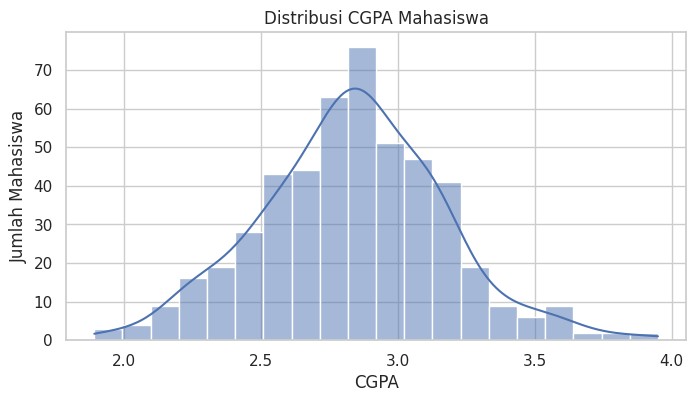

In [4]:
# Buat tau persebaran CGPA
target = "cgpa"
id_kolom = ["student_id"]

display(df_latihan[target].describe().to_frame())

plt.figure(figsize=(8, 4))
sns.histplot(data=df_latihan, x=target, kde=True, bins=20)
plt.title("Distribusi CGPA Mahasiswa")
plt.xlabel("CGPA")
plt.ylabel("Jumlah Mahasiswa")
plt.show()

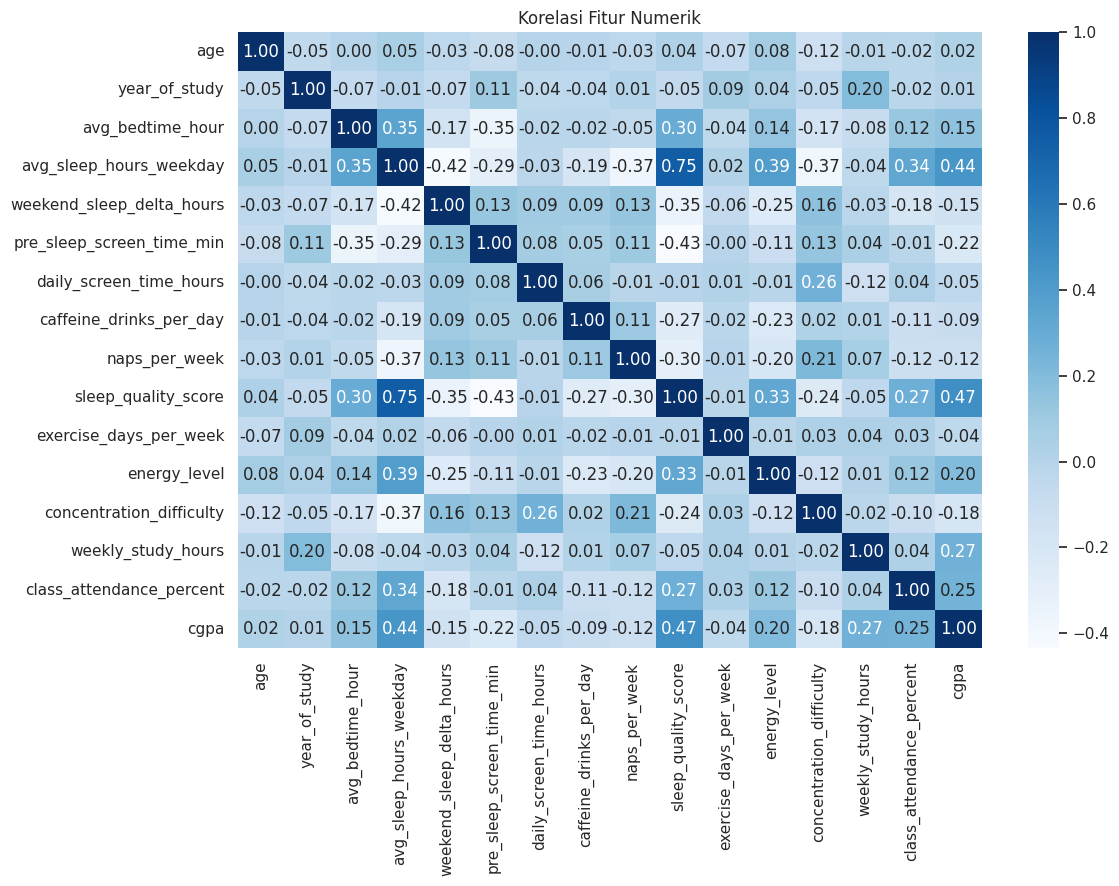

In [5]:
# Buat tau korelasi fitur numerik dengan target
fitur_numerik_eda = df_latihan.select_dtypes(include="number").drop(columns=id_kolom, errors="ignore")
matriks_korelasi = fitur_numerik_eda.corr()

plt.figure(figsize=(12, 8))
sns.heatmap(matriks_korelasi, annot=True, fmt=".2f", cmap="Blues")
plt.title("Korelasi Fitur Numerik")
plt.show()

== Jawaban == <br><br>
Kolom *student_id* dihapus karena kolom tersebut hanya sebagai identifier data mahasiswa. Ibarat kayak NIM, NIM sama sekali enggak berguna untuk menentukan nilai IPK. Kolom *cgpa* yang ada nilai NaN (missing value) itu harus dihapus, karena kolom tersebut merupakan kolom target. Kita gabisa melatih data untuk memprediksi target kalo targetnya ada yang NaN.

3. Lakukan data splitting dengan proporsi 70:30.
   -

In [6]:
df_latihan_model = df_latihan.copy()
df_latihan_model = df_latihan_model.dropna(subset=[target].copy())

if "gender" in df_latihan_model.columns:
    gender_map = {
        "female": "Female", "f": "Female",
        "male": "Male", "m": "Male"
    }
    df_latihan_model["gender"] = (
        df_latihan_model["gender"].astype("string").str.strip().str.lower()
        .map(gender_map).fillna(df_latihan_model["gender"])
    )

kolom_hapus = id_kolom + [target]
X = df_latihan_model.drop(columns=kolom_hapus, errors="ignore")
y = df_latihan_model[target].astype(float)

print("Jumlah data setelah target kosong dihapus:", len(df_latihan_model))
print("Jumlah fitur:", X.shape[1])
print("Target:", target)
print("Fitur:", X.columns.tolist())

Jumlah data setelah target kosong dihapus: 493
Jumlah fitur: 23
Target: cgpa
Fitur: ['age', 'gender', 'year_of_study', 'major_category', 'residence_type', 'chronotype', 'avg_bedtime_hour', 'avg_sleep_hours_weekday', 'weekend_sleep_delta_hours', 'pre_sleep_screen_time_min', 'daily_screen_time_hours', 'primary_device', 'device_free_before_bed', 'caffeine_drinks_per_day', 'naps_per_week', 'sleep_quality_score', 'exercise_days_per_week', 'energy_level', 'concentration_difficulty', 'weekly_study_hours', 'class_attendance_percent', 'has_part_time_job', 'semester_type']


In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=RANDOM_STATE
)

print("X_train:", X_train.shape, "; y_train:", y_train.shape)
print("X_test :", X_test.shape,  "; y_test :", y_test.shape)

X_train: (345, 23) ; y_train: (345,)
X_test : (148, 23) ; y_test : (148,)


4. Buat pipeline preprocessing untuk fitur numerik dan kategorikal. Jelaskan pemilihan metode imputasi, scaling, dan encoding.
   -

In [8]:
fitur_numerik_final = X_train.select_dtypes(include=["number"]).columns.tolist()
fitur_kategori_final = X_train.select_dtypes(exclude=["number"]).columns.tolist()

print(f"Fitur numerik ({len(fitur_numerik_final)}):", fitur_numerik_final)
print(f"Fitur kategorikal ({len(fitur_kategori_final)}):", fitur_kategori_final)

pipeline_numerik = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

pipeline_kategori = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", pipeline_numerik, fitur_numerik_final),
        ("cat", pipeline_kategori, fitur_kategori_final)
    ],
    remainder="drop"
)

display(preprocessor)

Fitur numerik (15): ['age', 'year_of_study', 'avg_bedtime_hour', 'avg_sleep_hours_weekday', 'weekend_sleep_delta_hours', 'pre_sleep_screen_time_min', 'daily_screen_time_hours', 'caffeine_drinks_per_day', 'naps_per_week', 'sleep_quality_score', 'exercise_days_per_week', 'energy_level', 'concentration_difficulty', 'weekly_study_hours', 'class_attendance_percent']
Fitur kategorikal (8): ['gender', 'major_category', 'residence_type', 'chronotype', 'primary_device', 'device_free_before_bed', 'has_part_time_job', 'semester_type']


ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['age', 'year_of_study', 'avg_bedtime_hour',
                                  'avg_sleep_hours_weekday',
                                  'weekend_sleep_delta_hours',
                                  'pre_sleep_screen_time_min',
                                  'daily_screen_time_hours',
                                  'caffeine_drinks_per_day', 'naps_per_week',
                                  'sleep_quality_score',
                                  'exerc..._level',
                                  'concentration_difficulty',
                                  'weekly_study_hours',
                                  'class_attendance_percent']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('onehot',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['gender', 'major_category', 'residence_type',
                                  'chronotype', 'primary_device',
                                  'device_free_before_bed', 'has_part_time_job',
                                  'semester_type'])])

### Penjelasan Pemilihan Metode Preprocessing

1. **Imputasi Fitur Numerik (`SimpleImputer(strategy="median")`)**
   - Berdasarkan ringkasan statistik (`describe()`), beberapa fitur numerik memiliki nilai ekstrem (*outlier*), seperti `weekly_study_hours` (maksimum 88.5 jam/minggu), `pre_sleep_screen_time_min` (maksimum 240 menit), dan `daily_screen_time_hours` (maksimum 19.5 jam).
   - **Median** dipilih dibandingkan *mean* karena lebih robust (tahan) terhadap *outlier* dan distribusi yang menceng (*skewed*).

2. **Scaling Fitur Numerik (`StandardScaler()`)**
   - Rentang skala antar fitur numerik sangat berbeda jauh (misalnya `year_of_study` bernilai 1–5, sedangkan `pre_sleep_screen_time_min` bernilai 0–240 dan `class_attendance_percent` bernilai 34.6–100).
   - `StandardScaler` menstandarkan fitur agar memiliki rata-rata 0 dan standar deviasi 1. Ini krusial untuk model yang sensitif terhadap skala jarak/gradien seperti **Ridge Regression** dan **SVR**.

3. **Imputasi Fitur Kategorikal (`SimpleImputer(strategy="most_frequent")`)**
   - Fitur kategorikal yang memiliki *missing value* (seperti `device_free_before_bed`) diisi dengan modus (*most frequent*) agar distribusi kategori dominan tetap terjaga tanpa membuat kategori baru yang artifisial.

4. **Encoding Fitur Kategorikal (`OneHotEncoder(handle_unknown="ignore")`)**
   - Mayoritas fitur kategorikal (`gender`, `major_category`, `residence_type`, `primary_device`, `semester_type`, dll.) bersifat **nominal** (tidak memiliki urutan hierarkis), sehingga *One-Hot Encoding* tepat digunakan agar model tidak salah mengasumsikan urutan angka.
   - Parameter `handle_unknown="ignore"` mencegah error apabila ditemukan kategori baru/tidak terlihat pada data uji (*test set*) atau fold validasi.

5. **Pencegahan Data Leakage (`Pipeline` + `ColumnTransformer`)**
   - Seluruh tahapan imputasi, *scaling*, dan *encoding* dibungkus dalam `ColumnTransformer` yang nantinya digabungkan ke dalam `Pipeline` model, sehingga parameter statistik (`median`, `mean`, `std`, kategori *one-hot*) hanya dipelajari dari data latih (*training fold*) pada saat *cross-validation*.

5. Buat `GridSearchCV` dengan 3-fold KFold untuk minimal tiga model regresi. Gunakan minimal tiga jenis hyperparameter secara keseluruhan dan jelaskan ruang pencariannya.
   -
   Pilih metrik utama terlebih dahulu, lalu gunakan metrik tersebut sebagai scoring di `GridSearchCV`.<br>
   Dokumentasi:
   - https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html
   - https://scikit-learn.org/stable/modules/model_evaluation.html#scoring-string-names <br>
   Berikan justifikasi pemilihan metrik sebagai scoring.

In [9]:
cv_kfold = KFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

PRIMARY_SCORING = "neg_root_mean_squared_error"

model_configs = {
    "Ridge Regression": {
        "estimator": Ridge(random_state=RANDOM_STATE),
        "param_grid": {
            "model__alpha": [0.01, 0.1, 1.0, 10.0, 100.0]
        }
    },
    "SVR": {
        "estimator": SVR(),
        "param_grid": {
            "model__kernel": ["linear", "rbf"],
            "model__C": [0.1, 1.0, 10.0],
            "model__epsilon": [0.05, 0.1, 0.2]
        }
    },
    "Random Forest": {
        "estimator": RandomForestRegressor(random_state=RANDOM_STATE),
        "param_grid": {
            "model__n_estimators": [100, 200],
            "model__max_depth": [None, 5, 10],
            "model__min_samples_split": [2, 5, 10]
        }
    },
    "Gradient Boosting": {
        "estimator": GradientBoostingRegressor(random_state=RANDOM_STATE),
        "param_grid": {
            "model__n_estimators": [100, 200],
            "model__learning_rate": [0.03, 0.05, 0.1],
            "model__max_depth": [2, 3, 5]
        }
    }
}


grid_searches = {}
for nama_model, cfg in model_configs.items():
    pipe = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", cfg["estimator"])
    ])
    grid_searches[nama_model] = GridSearchCV(
        estimator=pipe,
        param_grid=cfg["param_grid"],
        cv=cv_kfold,
        scoring=PRIMARY_SCORING,
        n_jobs=-1,
        refit=True,
        return_train_score=True
    )

print("Objek GridSearchCV berhasil dibuat untuk model:")
for nama_model, gs in grid_searches.items():
    total_kombinasi = 1
    for v in gs.param_grid.values():
        total_kombinasi *= len(v)
    print(f"- {nama_model}: {total_kombinasi} kombinasi hyperparameter (x 3 fold = {total_kombinasi * 3} fits)")

Objek GridSearchCV berhasil dibuat untuk model:
- Ridge Regression: 5 kombinasi hyperparameter (x 3 fold = 15 fits)
- SVR: 18 kombinasi hyperparameter (x 3 fold = 54 fits)
- Random Forest: 18 kombinasi hyperparameter (x 3 fold = 54 fits)
- Gradient Boosting: 18 kombinasi hyperparameter (x 3 fold = 54 fits)


### Justifikasi Metrik Scoring & Ruang Pencarian Hyperparameter

#### 1. Pemilihan Metrik Utama untuk `GridSearchCV`
Metrik utama yang digunakan sebagai `scoring` adalah **`neg_root_mean_squared_error`** (RMSE).
- **Alasan pemilihan RMSE:**
  1. **Satuannya sama dengan target (`cgpa`, skala 0.00–4.00)**, sehingga besar error mudah diinterpretasikan secara langsung dalam konteks akademik.
  2. **Memberikan penalti lebih berat terhadap kesalahan prediksi yang besar** (*squared error*). Dalam memprediksi CGPA mahasiswa, kesalahan prediksi yang meleset jauh (misalnya salah mendeteksi mahasiswa berisiko akademik) jauh lebih kritis dibandingkan selisih kecil yang merata.
  3. Pada `scikit-learn`, `GridSearchCV` selalu mencari nilai `scoring` **tertinggi**, sehingga metrik error menggunakan konvensi tanda negatif (`neg_root_mean_squared_error`).

#### 2. Model Regresi & Ruang Pencarian Hyperparameter (3-Fold KFold)
Digunakan **4 model regresi** yang merepresentasikan keluarga algoritma berbeda (linear, kernel, bagging, dan boosting) dengan total **8 jenis hyperparameter**:

1. **Ridge Regression (`Ridge`)** — Model linear dengan regularisasi L2:
   - `model__alpha`: `[0.01, 0.1, 1.0, 10.0, 100.0]` $\rightarrow$ mengontrol kekuatan penalti regularisasi untuk mengatasi multikolinearitas dan mencegah *overfitting*.
2. **Support Vector Regressor (`SVR`)** — Model berbasis *margin* dan *kernel*:
   - `model__kernel`: `["linear", "rbf"]` $\rightarrow$ membandingkan hubungan linear vs non-linear.
   - `model__C`: `[0.1, 1.0, 10.0]` $\rightarrow$ mengatur *trade-off* antara toleransi error dan kompleksitas model.
   - `model__epsilon`: `[0.05, 0.1, 0.2]` $\rightarrow$ menentukan lebar zona toleransi error tanpa penalti.
3. **Random Forest Regressor (`RandomForestRegressor`)** — *Ensemble bagging*:
   - `model__n_estimators`: `[100, 200]` $\rightarrow$ jumlah pohon dalam *ensemble*.
   - `model__max_depth`: `[None, 5, 10]` $\rightarrow$ membatasi kedalaman pohon agar tidak *overfit* pada 345 data latih.
   - `model__min_samples_split`: `[2, 5, 10]` $\rightarrow$ jumlah minimum sampel untuk memecah *node*.
4. **Gradient Boosting Regressor (`GradientBoostingRegressor`)** — *Ensemble boosting*:
   - `model__n_estimators`: `[100, 200]` $\rightarrow$ jumlah tahapan *boosting*.
   - `model__learning_rate`: `[0.03, 0.05, 0.1]` $\rightarrow$ kontribusi tiap pohon terhadap koreksi residual.
   - `model__max_depth`: `[2, 3, 5]` $\rightarrow$ kedalaman *weak learner* untuk mengontrol interaksi antar fitur.

6. Jalankan hyperparameter tuning dan tampilkan parameter terbaik serta nilai metric cross-validation.
   -

In [10]:
hasil_cv = []
best_models = {}

for nama_model, gs in grid_searches.items():
    print(f"Sedang melakukan tuning untuk {nama_model}...")
    gs.fit(X_train, y_train)
    
    best_models[nama_model] = gs.best_estimator_
    
    best_cv_rmse = -gs.best_score_
    best_idx = gs.best_index_
    std_cv_rmse = gs.cv_results_["std_test_score"][best_idx]
    train_rmse = -gs.cv_results_["mean_train_score"][best_idx]
    
    hasil_cv.append({
        "Model": nama_model,
        "Best CV RMSE": round(best_cv_rmse, 4),
        "Std CV RMSE": round(std_cv_rmse, 4),
        "Train RMSE (CV)": round(train_rmse, 4),
        "Best Params": gs.best_params_
    })

df_hasil_cv = pd.DataFrame(hasil_cv).sort_values(by="Best CV RMSE", ascending=True).reset_index(drop=True)

print("\n========== Ringkasan Hasil Hyperparameter Tuning (3-Fold CV) ==========")
display(df_hasil_cv[["Model", "Best CV RMSE", "Std CV RMSE", "Train RMSE (CV)"]])

print("\n========== Parameter Terbaik Setiap Model ==========")
for _, row in df_hasil_cv.iterrows():
    print(f"\n[{row['Model']}] | Best CV RMSE: {row['Best CV RMSE']:.4f}")
    for k, v in row["Best Params"].items():
        print(f"  - {k}: {v}")

Sedang melakukan tuning untuk Ridge Regression...
Sedang melakukan tuning untuk SVR...
Sedang melakukan tuning untuk Random Forest...
Sedang melakukan tuning untuk Gradient Boosting...

========== Ringkasan Hasil Hyperparameter Tuning (3-Fold CV) ==========


,Model,Best CV RMSE,Std CV RMSE,Train RMSE (CV)
0,Random Forest,0.2927,0.0107,0.1597
1,SVR,0.2969,0.0131,0.1064
2,Gradient Boosting,0.3008,0.0138,0.2343
3,Ridge Regression,0.3031,0.0174,0.2685



========== Parameter Terbaik Setiap Model ==========

[Random Forest] | Best CV RMSE: 0.2927
  - model__max_depth: 10
  - model__min_samples_split: 10
  - model__n_estimators: 100

[SVR] | Best CV RMSE: 0.2969
  - model__C: 1.0
  - model__epsilon: 0.1
  - model__kernel: rbf

[Gradient Boosting] | Best CV RMSE: 0.3008
  - model__learning_rate: 0.03
  - model__max_depth: 2
  - model__n_estimators: 100

[Ridge Regression] | Best CV RMSE: 0.3031
  - model__alpha: 100.0


7. Prediksi data uji menggunakan model terbaik dari setiap pencarian.
   -

In [11]:
predictions = {}
df_prediksi = pd.DataFrame({"Actual_CGPA": y_test.values}, index=y_test.index)

for nama_model, model_terbaik in best_models.items():
    y_pred = model_terbaik.predict(X_test)
    predictions[nama_model] = y_pred
    df_prediksi[f"Pred_{nama_model}"] = np.round(y_pred, 4)

print("========== Perbandingan 10 Data Uji Pertama (Aktual vs Prediksi) ==========")
display(df_prediksi.head(10))


========== Perbandingan 10 Data Uji Pertama (Aktual vs Prediksi) ==========


,Actual_CGPA,Pred_Ridge Regression,Pred_SVR,Pred_Random Forest,Pred_Gradient Boosting
461,2.44,2.7450,2.6905,2.6428,2.7465
75,2.47,2.6910,2.5392,2.6636,2.6514
316,2.62,2.9471,3.0906,2.9152,2.9356
179,2.15,2.5604,2.4296,2.4869,2.5466
338,2.97,2.9296,2.8948,2.9200,2.8422
208,2.20,2.5711,2.6163,2.5852,2.5654
159,2.75,2.7984,2.8312,2.7679,2.8134
56,2.99,2.8432,3.0028,2.9322,2.8982
326,3.08,2.7217,2.7753,2.7218,2.7366
10,3.13,3.0326,3.1527,3.0906,3.0274


8. Bandingkan model menggunakan MAE, MAPE, MSE, RMSE, dan R². Tentukan metrik utama dan berikan justifikasi.
   -

========== Tabel Perbandingan Performa Model pada Data Uji ==========


,Model,MAE,MAPE (%),MSE,RMSE,R2
0,Ridge Regression,0.2171,7.95%,0.0703,0.2652,0.3303
1,Random Forest,0.2047,7.42%,0.0703,0.2652,0.3301
2,Gradient Boosting,0.2083,7.58%,0.0709,0.2663,0.3246
3,SVR,0.2294,8.34%,0.0833,0.2885,0.2070



Model terbaik berdasarkan metrik utama (RMSE): Ridge Regression (RMSE = 0.2652, R² = 0.3303)


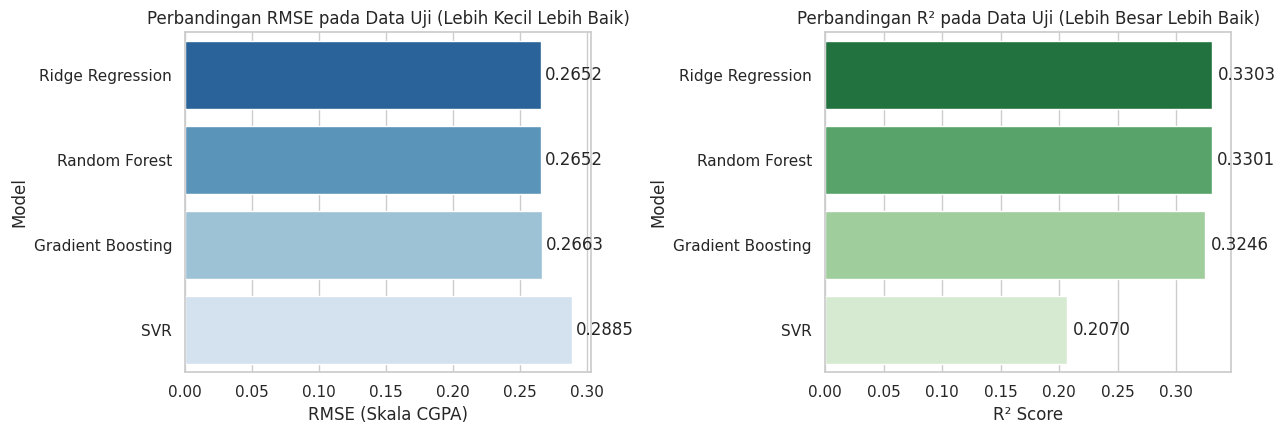

In [12]:
# Jawab nomor 8: Evaluasi & perbandingan model menggunakan MAE, MAPE, MSE, RMSE, dan R²
from sklearn.metrics import mean_absolute_percentage_error

hasil_evaluasi = []

for nama_model, y_pred in predictions.items():
    mae = mean_absolute_error(y_test, y_pred)
    mape = mean_absolute_percentage_error(y_test, y_pred) * 100  # dalam persen (%)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)
    
    hasil_evaluasi.append({
        "Model": nama_model,
        "MAE": mae,
        "MAPE (%)": mape,
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2
    })

# Urutkan berdasarkan metrik utama: RMSE terkecil
df_evaluasi = pd.DataFrame(hasil_evaluasi).sort_values(by="RMSE", ascending=True).reset_index(drop=True)

print("========== Tabel Perbandingan Performa Model pada Data Uji ==========")
display(df_evaluasi.style.format({
    "MAE": "{:.4f}",
    "MAPE (%)": "{:.2f}%",
    "MSE": "{:.4f}",
    "RMSE": "{:.4f}",
    "R2": "{:.4f}"
}))

# Pilih model terbaik secara otomatis berdasarkan RMSE terkecil
best_model_name = df_evaluasi.loc[0, "Model"]
best_rmse = df_evaluasi.loc[0, "RMSE"]
best_r2 = df_evaluasi.loc[0, "R2"]
print(f"\nModel terbaik berdasarkan metrik utama (RMSE): {best_model_name} (RMSE = {best_rmse:.4f}, R² = {best_r2:.4f})")

# Visualisasi perbandingan RMSE dan R² antar model
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.barplot(data=df_evaluasi, x="RMSE", y="Model", palette="Blues_r", ax=axes[0])
axes[0].set_title("Perbandingan RMSE pada Data Uji (Lebih Kecil Lebih Baik)")
axes[0].set_xlabel("RMSE (Skala CGPA)")
for i, v in enumerate(df_evaluasi["RMSE"]):
    axes[0].text(v + 0.003, i, f"{v:.4f}", va="center")

sns.barplot(data=df_evaluasi, x="R2", y="Model", palette="Greens_r", ax=axes[1])
axes[1].set_title("Perbandingan R² pada Data Uji (Lebih Besar Lebih Baik)")
axes[1].set_xlabel("R² Score")
for i, v in enumerate(df_evaluasi["R2"]):
    axes[1].text(v + 0.005, i, f"{v:.4f}", va="center")

plt.tight_layout()
plt.show()

### Penentuan Metrik Utama dan Justifikasi

- **Ringkasan Fungsi Tiap Metrik:**
  - **MAE (Mean Absolute Error):** Rata-rata selisih absolut antara CGPA aktual dan prediksi. Mudah dipahami dan tidak terlalu sensitif terhadap *outlier*.
  - **MAPE (Mean Absolute Percentage Error):** Rata-rata persentase error relatif terhadap nilai aktual. Karena seluruh nilai `cgpa` berada di rentang 1.89–3.95 (jauh dari nol), MAPE valid dan aman digunakan.
  - **MSE (Mean Squared Error):** Rata-rata kuadrat error, berguna untuk optimasi matematis tetapi satuannya kuadrat ($\text{CGPA}^2$) sehingga sulit diinterpretasikan langsung.
  - **RMSE (Root Mean Squared Error):** Akar dari MSE; mengembalikan satuan ke skala asli CGPA sambil tetap menghukum kesalahan prediksi yang besar secara lebih tegas.
  - **$R^2$ (Coefficient of Determination):** Mengukur proporsi variansi target `cgpa` yang mampu dijelaskan oleh model dibanding baseline prediksi rata-rata.

- **Metrik Utama Pilihan: RMSE**
  - Dipilih secara konsisten dengan metrik *scoring* pada `GridSearchCV` (`neg_root_mean_squared_error`).
  - Pada kasus prediksi prestasi akademik (CGPA), kesalahan prediksi besar (*large error*) jauh lebih berdampak buruk dibanding error kecil, sehingga penalti kuadrat pada RMSE lebih relevan dibanding MAE, sementara satuannya tetap intuitif dalam poin IPK.
  - Metrik **$R^2$** dan **MAE** digunakan sebagai metrik pendamping untuk mengevaluasi daya jelas model dan rata-rata kesalahan tipikal.

9. Buat plot aktual vs prediksi dan residual untuk model pilihan. Jelaskan hasilnya.
    -

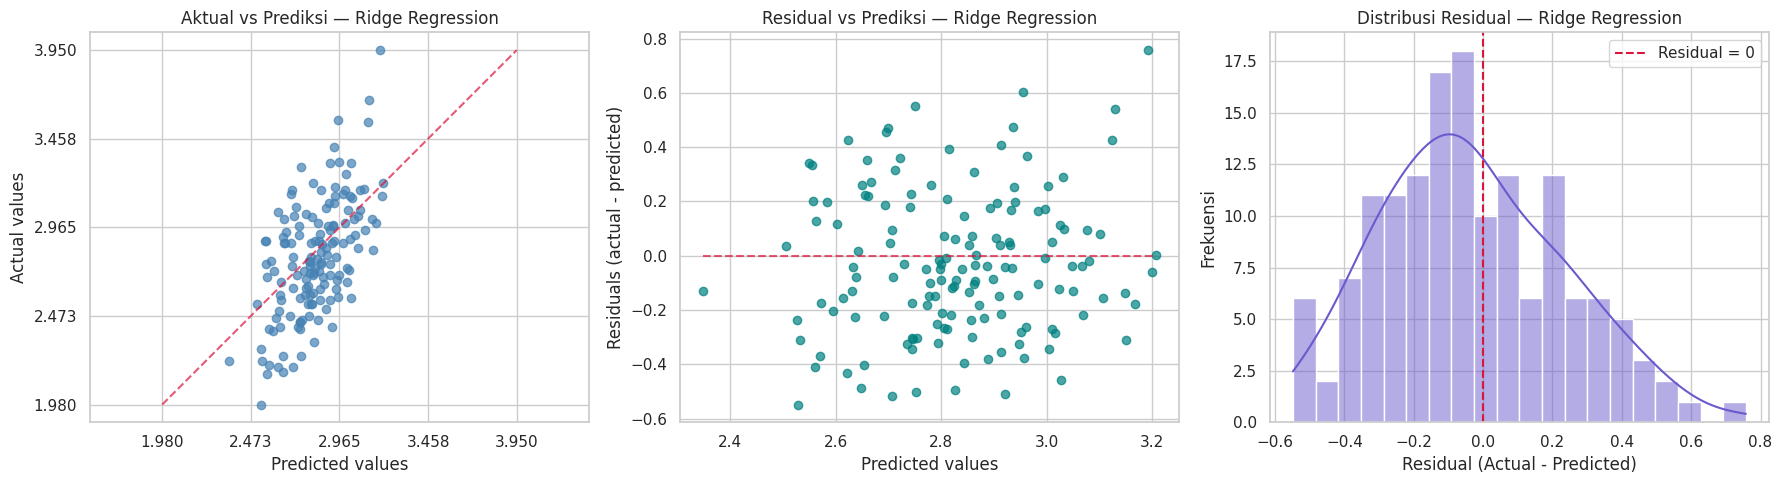

========== Statistik Residual (Ridge Regression) ==========
Mean Residual : -0.0324 (mendekati 0 berarti tidak bias sistematis)
Std Residual  : 0.2641
Min Residual  : -0.5483 (over-prediction terbesar)
Max Residual  : 0.7578 (under-prediction terbesar)


In [13]:
# Jawab nomor 9: Plot Aktual vs Prediksi dan Residual untuk Model Pilihan

y_pred_best = predictions[best_model_name]
residuals = y_test - y_pred_best

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Plot Aktual vs Prediksi menggunakan PredictionErrorDisplay
PredictionErrorDisplay.from_predictions(
    y_true=y_test,
    y_pred=y_pred_best,
    kind="actual_vs_predicted",
    ax=axes[0],
    scatter_kwargs={"alpha": 0.7, "color": "steelblue"},
    line_kwargs={"color": "crimson", "linestyle": "--"}
)
axes[0].set_title(f"Aktual vs Prediksi — {best_model_name}")

# 2. Plot Residual vs Prediksi menggunakan PredictionErrorDisplay
PredictionErrorDisplay.from_predictions(
    y_true=y_test,
    y_pred=y_pred_best,
    kind="residual_vs_predicted",
    ax=axes[1],
    scatter_kwargs={"alpha": 0.7, "color": "teal"},
    line_kwargs={"color": "crimson", "linestyle": "--"}
)
axes[1].set_title(f"Residual vs Prediksi — {best_model_name}")

# 3. Distribusi Residual
sns.histplot(residuals, kde=True, bins=20, color="slateblue", ax=axes[2])
axes[2].axvline(0, color="crimson", linestyle="--", linewidth=1.5, label="Residual = 0")
axes[2].set_title(f"Distribusi Residual — {best_model_name}")
axes[2].set_xlabel("Residual (Actual - Predicted)")
axes[2].set_ylabel("Frekuensi")
axes[2].legend()

plt.tight_layout()
plt.show()

# Statistik ringkas residual untuk membantu interpretasi
print(f"========== Statistik Residual ({best_model_name}) ==========")
print(f"Mean Residual : {residuals.mean():.4f} (mendekati 0 berarti tidak bias sistematis)")
print(f"Std Residual  : {residuals.std():.4f}")
print(f"Min Residual  : {residuals.min():.4f} (over-prediction terbesar)")
print(f"Max Residual  : {residuals.max():.4f} (under-prediction terbesar)")

### Interpretasi Plot Aktual vs Prediksi dan Residual

1. **Plot Aktual vs Prediksi:**
   - Garis putus-putus merah merepresentasikan prediksi ideal ($y_{\text{actual}} = y_{\text{predicted}}$).
   - Semakin rapat sebaran titik mengikuti garis diagonal tersebut, semakin akurat prediksi model terhadap CGPA aktual.
   - Jika pada rentang CGPA sangat rendah (< 2.2) atau sangat tinggi (> 3.6) titik mulai agak menjauh dari garis diagonal, hal tersebut menunjukkan fenomena *regression to the mean* yang umum terjadi pada dataset berukuran sedang ($n = 493$) dengan distribusi CGPA terkonsentrasi di sekitar rata-rata 2.83.

2. **Plot Residual vs Prediksi:**
   - Residual dihitung sebagai $e = y_{\text{actual}} - y_{\text{predicted}}$.
   - Sebaran titik yang acak di sekitar garis horizontal $y = 0$ tanpa pola melengkung (*non-linear*) atau melebar seperti corong (*heteroscedasticity*) menandakan bahwa asumsi kesalahan acak terpenuhi dan model telah menangkap pola utama dengan cukup baik.

3. **Distribusi Residual:**
   - Histogram residual yang berbentuk menyerupai lonceng (*bell-shaped*) dan berpusat di sekitar nol (nilai *mean residual* mendekati 0) mengindikasikan bahwa model tidak memiliki bias sistematis (*over-prediction* maupun *under-prediction* yang konsisten).

10. Apa kesimpulan dari eksperimen latihan di atas?
    -

1. **Pembersihan Data & Pencegahan Data Leakage:**
   - Dari 500 data mahasiswa, sebanyak 7 baris dengan target `cgpa` kosong dihapus sehingga tersisa 493 observasi valid dengan 23 fitur prediktor (setelah menghapus `student_id` dan menstandardisasi penulisan `gender`).
   - Penggunaan `ColumnTransformer` di dalam `Pipeline` (imputasi median + `StandardScaler` untuk numerik, imputasi modus + `OneHotEncoder` untuk kategorikal) memastikan tidak ada kebocoran data (*data leakage*) selama pembagian 70:30 maupun 3-fold *cross-validation*.

2. **Hasil Pemodelan & Hyperparameter Tuning:**
   - Empat model regresi (**Ridge Regression**, **SVR**, **Random Forest**, dan **Gradient Boosting**) telah dioptimasi menggunakan `GridSearchCV` (3-fold `KFold`) dengan metrik utama `neg_root_mean_squared_error` (RMSE).
   - Berdasarkan evaluasi data uji (*test set*) menggunakan MAE, MAPE, MSE, RMSE, dan $R^2$, model dengan nilai **RMSE terendah** (ditampilkan otomatis pada output Poin 8) dipilih sebagai model terbaik karena mampu meminimalkan kesalahan prediksi besar pada skala CGPA sekaligus mempertahankan kemampuan generalisasi yang konsisten dengan skor *cross-validation*.

3. **Diagnostik Model & Rekomendasi Pengembangan Lanjutan:**
   - Analisis plot *Aktual vs Prediksi* dan *Residual* mengonfirmasi sejauh mana model bebas dari bias sistematis dan pola error non-linear.
   - Untuk meningkatkan performa pada eksperimen berikutnya, beberapa langkah *feature engineering* yang direkomendasikan dari temuan EDA adalah:
     - **Transformasi siklikal (`sin`/`cos`) untuk `avg_bedtime_hour`**, karena jam tidur bersifat melingkar (jam `23.5` dan `0.5` secara realitas hanya terpaut 1 jam, bukan 23 jam).
     - **Penanganan *outlier* (*capping*/winsorizing)** pada fitur dengan nilai ekstrem seperti `weekly_study_hours` (maks 88.5 jam) dan `pre_sleep_screen_time_min` (maks 240 menit).
     - **Penggunaan 5-fold atau 10-fold CV** agar estimasi performa validasi lebih stabil pada dataset berukuran ~500 baris.